# 09 — Prediction Uncertainty and Reliability (FD001)

**Project:** Predictive Intelligence · **Phase 8**

## Objective

Every model so far returns one number: "47 cycles remaining". A single number hides how sure the model is. Two engines can both be estimated at 47, one with strong, clear evidence and one on thin evidence. A maintenance planner needs to know which is which.

This notebook attaches a **range** to each prediction and then checks, on engines the model has never seen, whether the range can be trusted. It answers:

1. How do we build a range around a prediction?
2. How often does the true remaining life fall inside it (**coverage**)?
3. How wide is it (**width**)? A range that is always "0 to 125" is always right and never useful.
4. Where does it fail, and what does that mean for how the system should speak?

**A prediction is not a guarantee.** Even a well-calibrated 90% range is *expected* to miss about one engine in ten. This notebook measures that, it does not remove it.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import add_training_rul, load_subset
from src.data.splits import engine_folds
from src.features.build import build_tabular_features, cap_rul
from src.models.uncertainty import (
    calibrated_band, conformal_correction, conformity_scores, make_quantile_model, raw_band)
from src.visualization import theme

theme.apply_theme()

TARGET_COVERAGE = 0.90
CAP = config.RUL_CAP

train, test, test_rul = load_subset("FD001")
sensors = config.FD001_SENSORS
train_table, feature_columns = build_tabular_features(
    add_training_rul(train), sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
train_table["target"] = cap_rul(train_table["rul"], CAP)

test_table, _ = build_tabular_features(test, sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
test_last = test_table.groupby("engine_id").tail(1).merge(test_rul, on="engine_id")
true_rul = test_last["true_rul"].to_numpy()
true_rul_capped = np.minimum(true_rul, CAP)


def make_point_model() -> XGBRegressor:
    # Same settings as the XGBoost baseline in notebook 05.
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                        colsample_bytree=0.8, n_jobs=-1, random_state=config.RANDOM_SEED)

## 2. The approach

**Two sources of uncertainty** are worth separating in words, even though the methods below measure their combined effect:

- **Noise in the engine and its sensors.** Two engines with identical readings can still fail at different times. No model can remove this.
- **The model's own ignorance.** With only 100 training engines, the model is unsure in situations it has seen rarely. More data would reduce this.

**Why not just ask the model how confident it is?** A standard regression model has no notion of confidence. Methods that bolt one on (for example the spread between several neural networks) often produce ranges that look reasonable but contain the truth far less often than claimed. So whatever method builds the range, the claim must be *checked against held-out engines*.

**Conformal prediction** makes that check part of the method:

1. Train the model on some engines.
2. On *other* engines, measure how wrong it was.
3. Use those measured errors to set the width of the range, so that it would have covered the chosen share (here 90%) of those engines.

Its appeal is that it assumes almost nothing about the model or the shape of the errors. Its one real assumption is that future engines resemble the ones used for calibration. If the fleet changes (a new fault mode, a new flight condition), the promise no longer holds.

**Use it** when you need ranges with a coverage level you can verify. **Be careful** that the promise is an average over engines, not a promise for each individual engine or for each stage of life, as section 5 shows.

### Out-of-fold predictions

To measure errors on engines the model did not train on, without giving up training data, we reuse the 5-fold engine split: each engine is predicted by a model trained on the other four folds. Every one of the 100 training engines then has honest "unseen" predictions. Rows before cycle 31 are left out of calibration, because no test engine is scored that early.

In [2]:
out_of_fold = pd.DataFrame(index=train_table.index, columns=["point", "low", "high"], dtype=float)

for train_rows, held_out_rows in engine_folds(train_table):
    fold_train, fold_held_out = train_table.iloc[train_rows], train_table.iloc[held_out_rows]
    features, target = fold_train[feature_columns], fold_train["target"]

    point_model = make_point_model().fit(features, target)
    low_model = make_quantile_model(0.05, config.RANDOM_SEED).fit(features, target)
    high_model = make_quantile_model(0.95, config.RANDOM_SEED).fit(features, target)

    low, high = raw_band(low_model, high_model, fold_held_out[feature_columns])
    out_of_fold.iloc[held_out_rows, 0] = np.clip(point_model.predict(fold_held_out[feature_columns]), 0, CAP)
    out_of_fold.iloc[held_out_rows, 1] = low
    out_of_fold.iloc[held_out_rows, 2] = high

calibration_rows = (train_table["cycle"] >= 31).to_numpy()
calibration_truth = train_table.loc[calibration_rows, "target"].to_numpy()
calibration = out_of_fold[calibration_rows]
print(f"Calibration predictions: {calibration_rows.sum():,} rows from {train_table['engine_id'].nunique()} engines, none seen in training by the model that predicted them")

Calibration predictions: 17,631 rows from 100 engines, none seen in training by the model that predicted them


## 3. Method A — the same margin for every engine

The simplest conformal range: take the absolute errors of the point model on the calibration predictions, find the value that 90% of them fall below, and use it as a ± margin on every prediction.

In [3]:
absolute_errors = np.abs(calibration_truth - calibration["point"].to_numpy())
constant_margin = conformal_correction(absolute_errors, TARGET_COVERAGE)
print(f"90% of out-of-fold errors are within ±{constant_margin:.1f} cycles")

90% of out-of-fold errors are within ±24.4 cycles


This is honest but blunt. It gives an engine estimated at 10 cycles the same ± margin as an engine estimated at 80. Notebook 05 showed the model is far more accurate near failure than in mid-life, so a fixed margin is too wide where precision matters most and possibly too narrow elsewhere.

## 4. Method B — a range that adapts to the engine

**Quantile regression.** Instead of training a model to predict the typical RUL, we train two more models with a different goal:

- a **low** model, trained so that the truth is above its output about 95% of the time, and
- a **high** model, trained so that the truth is below its output about 95% of the time.

Between them lies a band meant to contain the truth 90% of the time. Because each is a full model of the sensors, the band can be narrow for one engine and wide for another.

**The catch.** Nothing forces these models to be right about their own percentages on new engines. So we check on the out-of-fold predictions, and correct.

**Conformalized quantile regression (CQR).** For each calibration prediction, measure how far the truth fell *outside* the band (a negative number if it was inside). Take the 90% point of those distances and add it to both ends of every band. If the raw band was too narrow, this widens it; if too wide, it narrows it.

In [4]:
inside_raw_band = (calibration_truth >= calibration["low"]) & (calibration_truth <= calibration["high"])
scores = conformity_scores(calibration["low"].to_numpy(), calibration["high"].to_numpy(), calibration_truth)
cqr_correction = conformal_correction(scores, TARGET_COVERAGE)

print(f"Raw quantile band on out-of-fold predictions: covers {inside_raw_band.mean():.1%} (target {TARGET_COVERAGE:.0%}), "
      f"average width {(calibration['high'] - calibration['low']).mean():.1f} cycles")
print(f"Conformal correction: {cqr_correction:+.2f} cycles added to each end")

Raw quantile band on out-of-fold predictions: covers 88.4% (target 90%), average width 39.2 cycles
Conformal correction: +0.54 cycles added to each end


**Findings.**

- The uncorrected quantile band already covers 88.4% of the out-of-fold cases, close to the 90% target. The quantile models are nearly honest about their own percentages.
- The conformal correction is therefore small: about half a cycle added to each end.
- A small correction is good news. It means the adaptive shape of the band comes from the models, and the calibration step is only a fine adjustment. Had the correction been large, the band would have been mostly a fixed margin in disguise.

## 5. Checking the ranges on the test set

The final models are trained on all 100 training engines. The margins come from the out-of-fold calibration above. The test set is used only to check.

**How the cap affects the check.** The models were trained on RUL capped at 125 (decision D-008), so no range can extend above 125. When a range's upper end *is* 125, it should be read as "125 or more". Coverage is therefore measured two ways:

- against the **capped truth** (what the models were asked to predict), which treats "upper end at 125" as open-ended, and
- against the **truth as given**, reading the upper end literally. This is harsher: an engine with 140 cycles left can never be inside a range that stops at 125.

In [5]:
final_point = make_point_model().fit(train_table[feature_columns], train_table["target"])
final_low = make_quantile_model(0.05, config.RANDOM_SEED).fit(train_table[feature_columns], train_table["target"])
final_high = make_quantile_model(0.95, config.RANDOM_SEED).fit(train_table[feature_columns], train_table["target"])

point = np.clip(final_point.predict(test_last[feature_columns]), 0, CAP)
raw_low, raw_high = raw_band(final_low, final_high, test_last[feature_columns])

ranges = {
    "A. Constant margin": (np.clip(point - constant_margin, 0, CAP), np.clip(point + constant_margin, 0, CAP)),
    "B1. Quantile band, uncorrected": (np.clip(raw_low, 0, CAP), np.clip(raw_high, 0, CAP)),
    "B2. Quantile band + conformal (CQR)": calibrated_band(raw_low, raw_high, cqr_correction, 0, CAP),
}

summary = {}
for name, (low, high) in ranges.items():
    summary[name] = {
        "coverage, capped truth (%)": ((true_rul_capped >= low) & (true_rul_capped <= high)).mean() * 100,
        "coverage, truth as given (%)": ((true_rul >= low) & (true_rul <= high)).mean() * 100,
        "average width (cycles)": (high - low).mean(),
        "truth below range (failed sooner)": int((true_rul_capped < low).sum()),
        "truth above range (lasted longer)": int((true_rul_capped > high).sum()),
        "ranges ending at the cap": int((high >= CAP - 1e-6).sum()),
    }
pd.DataFrame(summary).T.round(1)

,"coverage, capped truth (%)","coverage, truth as given (%)",average width (cycles),truth below range (failed sooner),truth above range (lasted longer),ranges ending at the cap
A. Constant margin,89.0,80.0,42.1,3.0,8.0,32.0
"B1. Quantile band, uncorrected",95.0,84.0,43.5,3.0,2.0,49.0
B2. Quantile band + conformal (CQR),95.0,84.0,44.3,3.0,2.0,51.0


In [6]:
bands = pd.cut(true_rul, bins=[0, 30, 60, 90, 125, 150], labels=["1-30", "31-60", "61-90", "91-125", "126-145"])
by_band = pd.DataFrame({"engines": pd.Series(true_rul).groupby(bands, observed=True).size()})
for short_name, key in [("A", "A. Constant margin"), ("CQR", "B2. Quantile band + conformal (CQR)")]:
    low, high = ranges[key]
    covered = pd.Series((true_rul_capped >= low) & (true_rul_capped <= high))
    by_band[f"{short_name} coverage (%)"] = covered.groupby(bands, observed=True).mean() * 100
    by_band[f"{short_name} width"] = pd.Series(high - low).groupby(bands, observed=True).mean()
by_band.index.name = "true RUL"
by_band.round(1)

,engines,A coverage (%),A width,CQR coverage (%),CQR width
true RUL,,,,,
1-30,25,100.0,41.799999,88.0,26.200001
31-60,14,100.0,48.900002,100.0,46.299999
61-90,15,73.3,47.599998,93.3,63.400002
91-125,35,85.7,39.299999,97.1,49.900002
126-145,11,81.8,35.599998,100.0,39.000000


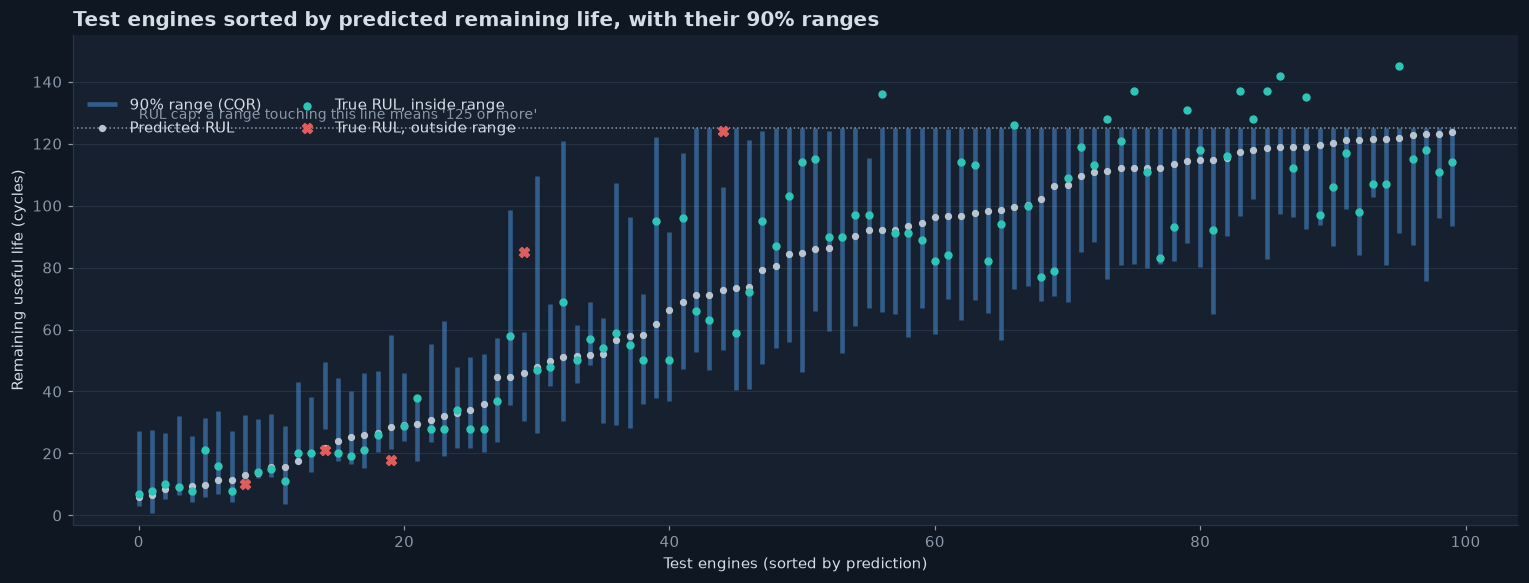

In [7]:
cqr_low, cqr_high = ranges["B2. Quantile band + conformal (CQR)"]
order = np.argsort(point)
positions = np.arange(len(order))
covered = (true_rul_capped >= cqr_low) & (true_rul_capped <= cqr_high)

fig, ax = plt.subplots(figsize=(14, 5.4))
ax.vlines(positions, cqr_low[order], cqr_high[order], color=theme.BLUE, alpha=0.55, linewidth=3, label="90% range (CQR)")
ax.scatter(positions, point[order], color=theme.SILVER, s=14, zorder=3, label="Predicted RUL")
ax.scatter(positions[covered[order]], true_rul[order][covered[order]], color=theme.TEAL, s=20, zorder=4,
           label="True RUL, inside range")
ax.scatter(positions[~covered[order]], true_rul[order][~covered[order]], color=theme.RED, s=42, marker="X", zorder=5,
           label="True RUL, outside range")
ax.axhline(CAP, color=theme.MUTED, linestyle=":", linewidth=1)
ax.text(0, CAP + 3, "RUL cap: a range touching this line means '125 or more'", color=theme.MUTED, fontsize=9)
ax.set_title("Test engines sorted by predicted remaining life, with their 90% ranges")
ax.set_xlabel("Test engines (sorted by prediction)")
ax.set_ylabel("Remaining useful life (cycles)")
ax.set_ylim(-3, 155)
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0.0, 0.9))
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [8]:
misses = test_last[["engine_id", "cycle"]].assign(
    predicted=point.round(1), range_low=cqr_low.round(1), range_high=cqr_high.round(1), true_rul=true_rul)[~covered]
misses["what happened"] = np.where(misses["true_rul"] < misses["range_low"], "failed sooner than the range", "lasted longer than the range")
misses.rename(columns={"cycle": "cycles recorded"}).sort_values("true_rul")

,engine_id,cycles recorded,predicted,range_low,range_high,true_rul,what happened
41,42,156,13.200000,10.400000,32.299999,10,failed sooner than the range
40,41,123,28.500000,21.299999,58.200001,18,failed sooner than the range
36,37,121,21.600000,28.000000,49.400002,21,failed sooner than the range
92,93,244,45.900002,30.400000,59.099998,85,lasted longer than the range
11,12,217,72.800003,53.400002,105.900002,124,lasted longer than the range


In [9]:
width = cqr_high - cqr_low
fifths = pd.qcut(point, 5, labels=["lowest fifth", "2nd", "3rd", "4th", "highest fifth"])
pd.DataFrame({
    "predicted RUL (mean)": pd.Series(point).groupby(fifths, observed=True).mean(),
    "range width (mean)": pd.Series(width).groupby(fifths, observed=True).mean(),
}).round(1).T

,lowest fifth,2nd,3rd,4th,highest fifth
predicted RUL (mean),15.9,44.900002,82.099998,105.300003,119.800003
range width (mean),24.9,43.500000,66.900002,50.900002,35.299999


### A consistency check: is the estimate inside its own range?

The point model and the two quantile models are trained separately, so nothing forces the estimate to lie between the two ends. A range that excludes its own estimate would be confusing to show to anyone.

In [10]:
from src.models.uncertainty import enclose_point

outside_own_range = (point < cqr_low) | (point > cqr_high)
print(f"Test engines whose estimate lies outside its own range: {int(outside_own_range.sum())} of {len(point)}")
print(test_last.loc[outside_own_range, ["engine_id"]].assign(
    predicted=point[outside_own_range].round(1), range_low=cqr_low[outside_own_range].round(1),
    range_high=cqr_high[outside_own_range].round(1), true_rul=true_rul[outside_own_range]).to_string(index=False))

enclosed_low, enclosed_high = enclose_point(cqr_low, cqr_high, point)
enclosed_coverage = ((true_rul_capped >= enclosed_low) & (true_rul_capped <= enclosed_high)).mean() * 100
print()
print(f"If every range is stretched to include its estimate: coverage {enclosed_coverage:.0f}%, "
      f"average width {(enclosed_high - enclosed_low).mean():.1f} cycles")

Test engines whose estimate lies outside its own range: 1 of 100
 engine_id  predicted  range_low  range_high  true_rul
        37       21.6       28.0   49.400002        21

If every range is stretched to include its estimate: coverage 95%, average width 44.4 cycles


**Findings on the test set.**

- **Both methods reach roughly the promised coverage.** The constant margin covers 89% of test engines and CQR covers 95%, against a 90% target. With only 100 engines, a method that is exactly right would typically land anywhere from about 84% to 96%, so both results are consistent with the target. CQR sits at the cautious end of that range.
- **The two methods cost about the same on average** (42 against 44 cycles wide) but spend the width very differently, and that is the reason to prefer CQR:
  - The **constant margin** gives an engine with 10 cycles left a range about 42 cycles wide. It is always "right" there and tells the planner almost nothing. In the 61-90 band it covers only 73%.
  - **CQR** is about 26 cycles wide for engines within 30 cycles of failure, and about 63 wide in the 61-90 band, with coverage between 88% and 100% in every band.
- **The range is narrowest at the two ends and widest in the middle.** Engines predicted around 82 cycles get ranges about 67 cycles wide. That is the model being honest: mid-life, when drift has begun but is not yet strong, is where it knows least. Near failure the evidence is clear. For apparently healthy engines the range is short only because its upper end is pinned at the cap.
- **Half of all ranges (51 of 100) end at the cap.** For those engines the honest statement is "at least N cycles", not a two-sided range.
- **Measured against the truth as given, coverage is 84%.** The shortfall is the engines with more than 125 cycles left, which a capped model cannot enclose. This is the price of decision D-008, stated openly.

**The five misses.**

- Three engines **failed sooner** than their range allowed: test engines 42, 41 and 37, with true RUL of 10, 18 and 21. These are the misses that matter for safety. Engine 42 missed by less than one cycle; engine 37 by seven.
- Two engines **lasted longer** than their range (93 and 12). These are the same two engines that produced the largest errors in notebook 05.
- All three "failed sooner" misses are in the 1-30 band, where coverage is 88% (22 of 25). With 25 engines that is not statistically different from 90%, but it is the band where a miss costs most, so it must not be glossed over: **the ranges are tightest exactly where an error is most serious.**

**The consistency check.** One test engine (37) has an estimate that lies below its own range, because the three models are trained separately. In the application every range will be stretched to include its estimate. That rule was adopted after looking at these test results, so the 95% figure above remains the headline; the stretched version is reported only for transparency.

## 6. Saving the uncertainty model

The application in Phase 11 will need the same three models and the same correction, so they are saved together with the settings they were built with.

In [11]:
models_dir = project_root / "models"
joblib.dump(final_point, models_dir / "fd001_xgboost_point.joblib")
joblib.dump(final_low, models_dir / "fd001_xgboost_q05.joblib")
joblib.dump(final_high, models_dir / "fd001_xgboost_q95.joblib")

cqr_summary = summary["B2. Quantile band + conformal (CQR)"]
settings = {
    "subset": "FD001", "target_coverage": TARGET_COVERAGE, "rul_cap": CAP,
    "cqr_correction_cycles": round(float(cqr_correction), 4), "constant_margin_cycles": round(float(constant_margin), 4),
    "calibration": "5-fold out-of-fold predictions by engine, rows with cycle >= 31",
    "test_coverage_capped_truth_percent": round(float(cqr_summary["coverage, capped truth (%)"]), 1),
    "test_average_width_cycles": round(float(cqr_summary["average width (cycles)"]), 1),
    "features": feature_columns,
}
(project_root / "experiments" / "fd001_uncertainty.json").write_text(json.dumps(settings, indent=1))
pd.DataFrame(summary).T.round(3).to_csv(project_root / "experiments" / "fd001_uncertainty_test.csv", index_label="method")
print("Saved 3 models and experiments/fd001_uncertainty.json")

Saved 3 models and experiments/fd001_uncertainty.json


## 7. Conclusions

| Question | Answer |
|---|---|
| How is the range built? | Two quantile models (5% and 95%) plus a conformal correction measured on out-of-fold engines (CQR) |
| Coverage on the test set | 95% of 100 engines against a 90% target (capped truth); 84% against the truth as given |
| Width | About 44 cycles on average: about 26 near failure, about 67 in mid-life |
| Better than a fixed margin? | Same average width, but informative where it matters and with steadier coverage across the life stages |
| Where does it fail? | 5 of 100 engines; 3 failed sooner than the range, all with 21 or fewer cycles left |

### A prediction is not a guarantee

What the 90% range means: across many engines like those it was calibrated on, the true remaining life falls inside about nine times in ten. What it does **not** mean:

- It is not a promise about any single engine. Engine 37 had a range of 28 to 49 and failed after 21.
- It is not a promise for each stage of life separately. Coverage is an average over the fleet.
- It does not hold if the engine differs from the calibration fleet: another fault mode, another flight condition, a sensor fault, or an engine whose early cycles were not recorded.
- It says nothing about engines beyond the cap except "at least 125".

### Rules this sets for the assistant (Phase 10)

1. Always give the range with the estimate, never the estimate alone.
2. When the upper end is at the cap, say "at least" and do not quote an upper number.
3. Describe the range as where the answer usually falls, and state that roughly one engine in ten falls outside.
4. For engines with a low estimate, stress that the engine may fail sooner than the lower end, and that the estimate cannot replace inspection.
5. Never describe the range as a safe operating window.

**Limitations.** One hundred test engines give a coarse estimate of coverage (a few percentage points either way). Calibration rows from the same engine are related, so the formal conformal guarantee holds only approximately; the test-set check is the real evidence. Only the XGBoost model was given ranges. The method measures total uncertainty and does not separate noise from model ignorance. Simulated data from one fault mode and one flight condition.

## 8. Next steps

**Phase 9 - evaluation and experiments:** tuning, ablations, sensitivity to seeds, and the same pipeline on FD002, FD003 and FD004.